# Grover's Algorithm for Financial Anomaly Detection

Hybrid quantum-classical outlier detection over 20 S&P 500 technology stocks.
Companion code for *Using Grover's Algorithm to Find Anomalies and Outliers in
Financial Markets with Classical Preprocessing* (CPS840).

**Pipeline**

1. Classical preprocessing: z-score three fundamentals (trailing P/E, return on
   equity, dividend yield) and threshold them into binary outlier indicators.
2. Quantum encoding: map each stock to one of 32 basis states of a 5-qubit
   register and mark the outliers with a `Diagonal` phase-flip oracle.
3. Amplitude amplification: one Grover iteration per metric, simulated on
   `AerSimulator` with a depolarizing NISQ noise model.
4. Quantum counting: phase estimation on the Grover operator to estimate how
   many states are marked.

Two experiments are run. **Experiment 1** thresholds classically and marks the
resulting binary indicators. **Experiment 2** amplitude-encodes the raw
|z-score| vector and lets quantum counting tune the threshold inside the loop,
moving the decision logic out of the classical preprocessor.

In [1]:
from __future__ import annotations

from pathlib import Path
from typing import Iterable, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Gate
from qiskit.circuit.library import QFT, Diagonal
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from scipy.stats import zscore

## Configuration

The register is sized to the dataset: 20 stocks need 5 qubits (32 basis
states), with the 12 unused states left unmarked. Counting uses 3 extra
qubits, so the counting circuits are 8 qubits wide.

In [2]:
DATA_PATH = Path("tech_stock_data.csv")
FIGURE_DIR = Path("figures")

TICKERS = [
    "AAPL", "MSFT", "GOOG", "AMZN", "IBM",
    "ORCL", "INTC", "NVDA", "ADBE", "CSCO",
    "CRM", "TXN", "QCOM", "HPQ", "DELL",
    "ACN", "AMD", "AVGO", "SAP", "ADP",
]
METRICS = ["trailingPE", "returnOnEquity", "dividendYield"]
METRIC_LABELS = {
    "trailingPE": "Trailing P/E",
    "returnOnEquity": "Return on Equity",
    "dividendYield": "Dividend Yield",
}
FLAG_COLUMNS = [f"{metric}_outlier" for metric in METRICS]

N_SYSTEM_QUBITS = 5
N_STATES = 2 ** N_SYSTEM_QUBITS
N_COUNTING_QUBITS = 3
GROVER_ITERATIONS = 1
SHOTS = 1024
Z_THRESHOLD = 2.0
DEPOLARIZING_RATE = 0.01
SEED = 1234

FIGURE_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
%config InlineBackend.figure_formats = ["svg"]


def save_figure(fig: plt.Figure, name: str) -> None:
    """Write a figure to `figures/<name>.svg`."""
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")

## 1. Data

`tech_stock_data.csv` is the snapshot the paper was written against, pulled
from Yahoo Finance via `yfinance`. It is committed so the whole notebook is
reproducible offline; set `REFRESH_DATA = True` to re-pull live fundamentals,
which will change every number downstream.

In [3]:
REFRESH_DATA = False

FIELDS = ["symbol", "shortName", "industry", "sector", "trailingPE",
          "forwardPE", "priceToBook", "dividendYield", "returnOnEquity"]


def fetch_fundamentals(tickers: Sequence[str]) -> pd.DataFrame:
    """Download the fundamental fields for `tickers` from Yahoo Finance."""
    import yfinance as yf

    rows = []
    for ticker in tickers:
        info = yf.Ticker(ticker).info
        rows.append({field: info.get(field) for field in FIELDS})
    return pd.DataFrame(rows)


if REFRESH_DATA:
    fetch_fundamentals(TICKERS).to_csv(DATA_PATH, index=False)

stocks = pd.read_csv(DATA_PATH)
stocks.columns = stocks.columns.str.strip()
stocks[["symbol", "shortName", *METRICS]]

,symbol,shortName,trailingPE,returnOnEquity,dividendYield
0,AAPL,Apple Inc.,34.585712,1.36520,0.44
1,MSFT,Microsoft Corporation,30.503632,0.34291,0.87
2,GOOG,Alphabet Inc.,20.366915,0.32908,0.48
3,AMZN,"Amazon.com, Inc.",35.119564,0.24290,NaN
4,IBM,International Business Machines,38.482864,0.24057,2.60
5,ORCL,Oracle Corporation,33.279343,1.03741,1.08
6,INTC,Intel Corporation,NaN,-0.17891,2.24
7,NVDA,NVIDIA Corporation,36.695580,1.19177,0.04
8,ADBE,Adobe Inc.,35.137140,0.36313,NaN
9,CSCO,"Cisco Systems, Inc.",26.600878,0.20019,2.64


## 2. Classical preprocessing

Each metric is z-scored (missing values imputed with the metric median) and
thresholded at |z| > 2.0. If a threshold flags nothing at all it is stepped
down until the dataset yields at least one outlier, so the pipeline never
hands an empty oracle to Grover.

In [4]:
def flag_outliers(df: pd.DataFrame, threshold: float) -> pd.DataFrame:
    """Add per-metric z-scores, binary outlier flags, and a composite score."""
    flagged = df.copy()
    for metric in METRICS:
        filled = flagged[metric].fillna(flagged[metric].median())
        flagged[f"{metric}_filled"] = filled
        flagged[f"{metric}_z"] = zscore(filled)
        flagged[f"{metric}_outlier"] = (flagged[f"{metric}_z"].abs() > threshold).astype(int)
    flagged["composite_score"] = flagged[FLAG_COLUMNS].sum(axis=1)
    return flagged


def flag_outliers_adaptive(
    df: pd.DataFrame,
    threshold: float = Z_THRESHOLD,
    step: float = 0.25,
    min_threshold: float = 0.5,
) -> tuple[pd.DataFrame, float]:
    """Relax the z-threshold until at least one outlier is flagged."""
    while True:
        flagged = flag_outliers(df, threshold)
        if flagged["composite_score"].sum() > 0 or threshold <= min_threshold:
            return flagged, threshold
        threshold = max(threshold - step, min_threshold)


processed, threshold_used = flag_outliers_adaptive(stocks)
n_flags = int(processed[FLAG_COLUMNS].to_numpy().sum())

print(f"threshold |z| > {threshold_used:.2f}: {n_flags} outlier flags")
processed.loc[processed["composite_score"] > 0,
              ["symbol", *[f"{m}_z" for m in METRICS], *FLAG_COLUMNS]]

threshold |z| > 2.00: 6 outlier flags


,symbol,trailingPE_z,returnOnEquity_z,dividendYield_z,trailingPE_outlier,returnOnEquity_outlier,dividendYield_outlier
0,AAPL,-0.176921,2.491586,-1.312054,0,1,0
7,NVDA,-0.087607,2.047430,-1.735809,0,1,0
13,HPQ,-1.204959,-0.297537,2.311058,0,0,1
16,AMD,2.439777,-0.930620,0.096934,1,0,0
17,AVGO,2.058714,-0.624528,-0.422167,1,0,0
18,SAP,2.184637,-0.823851,-0.814141,1,0,0


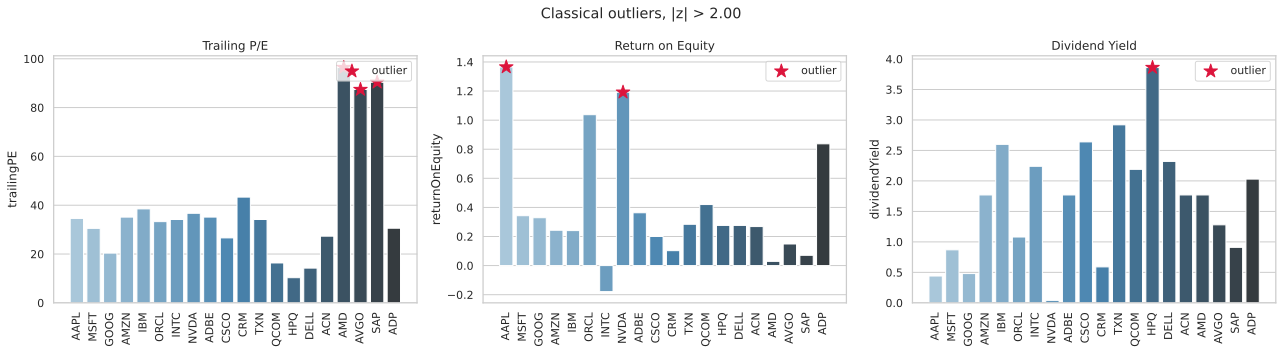

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, METRICS):
    sns.barplot(data=processed, x="symbol", y=f"{metric}_filled",
                hue="symbol", palette="Blues_d", legend=False, ax=ax)
    outliers = processed[processed[f"{metric}_outlier"] == 1]
    ax.scatter(outliers.index, outliers[f"{metric}_filled"],
               marker="*", s=200, color="crimson", zorder=5, label="outlier")
    ax.set_title(METRIC_LABELS[metric])
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=90)
    ax.legend(loc="upper right")
fig.suptitle(f"Classical outliers, |z| > {threshold_used:.2f}")
fig.tight_layout()
save_figure(fig, "01_classical_outliers")

## 3. Quantum building blocks

### Oracle

The oracle is a diagonal unitary that multiplies the amplitude of every marked
basis state by -1 and leaves the rest untouched. Building it from
`Diagonal` rather than multi-controlled logic keeps the circuit shallow, which
matters under NISQ noise.

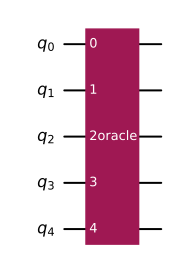

In [6]:
def diagonal_oracle(marked: Iterable[int], n_states: int = N_STATES) -> Gate:
    """Phase-flip oracle: |i> -> -|i> for every i in `marked`."""
    marked = set(marked)
    diagonal = [-1 if state in marked else 1 for state in range(n_states)]
    return Diagonal(np.array(diagonal)).to_gate(label="oracle")


def marked_indices(df: pd.DataFrame, flag_column: str) -> list[int]:
    """Row indices flagged as outliers, i.e. the basis states to mark."""
    return df.index[df[flag_column] == 1].tolist()


oracles = {metric: diagonal_oracle(marked_indices(processed, f"{metric}_outlier"))
           for metric in METRICS}

preview = QuantumCircuit(N_SYSTEM_QUBITS)
preview.append(oracles["trailingPE"], range(N_SYSTEM_QUBITS))
fig = preview.draw("mpl")
save_figure(fig, "02_oracle")
fig

### Grover operator and circuit

The diffusion operator is the textbook inversion about the mean, built from
Hadamards, X gates and one multi-controlled X. One Grover iteration is used
throughout, which is the optimum predicted by `floor(pi/4 * sqrt(N/M))` for
the small marked-set sizes here.

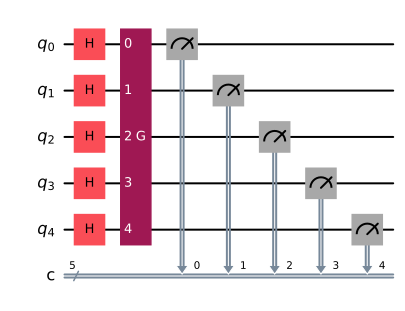

In [7]:
def diffusion_operator(n_qubits: int) -> QuantumCircuit:
    """Inversion about the mean on `n_qubits`."""
    qc = QuantumCircuit(n_qubits, name="diffuser")
    qc.h(range(n_qubits))
    qc.x(range(n_qubits))
    qc.h(n_qubits - 1)
    qc.mcx(list(range(n_qubits - 1)), n_qubits - 1, mode="noancilla")
    qc.h(n_qubits - 1)
    qc.x(range(n_qubits))
    qc.h(range(n_qubits))
    return qc


def grover_operator(oracle: Gate, n_qubits: int = N_SYSTEM_QUBITS) -> Gate:
    """One Grover iteration G = (diffusion)(oracle), as a controllable gate."""
    qc = QuantumCircuit(n_qubits, name="G")
    qc.append(oracle, range(n_qubits))
    qc.compose(diffusion_operator(n_qubits), inplace=True)
    return qc.to_gate(label="G")


def grover_circuit(
    oracle: Gate,
    n_qubits: int = N_SYSTEM_QUBITS,
    iterations: int = GROVER_ITERATIONS,
) -> QuantumCircuit:
    """Uniform superposition, `iterations` Grover steps, then measure."""
    qc = QuantumCircuit(n_qubits, n_qubits)
    qc.h(range(n_qubits))
    operator = grover_operator(oracle, n_qubits)
    for _ in range(iterations):
        qc.append(operator, range(n_qubits))
    qc.measure(range(n_qubits), range(n_qubits))
    return qc


fig = grover_circuit(oracles["trailingPE"]).draw("mpl")
save_figure(fig, "03_grover_circuit")
fig

### Quantum counting

Quantum counting is phase estimation on the Grover operator. The eigenphase
`theta` of G satisfies `sin^2(theta / 2) = M / N`, so a counting register of
`t` qubits measuring the value `v` estimates

`M = N * sin^2(pi * v / 2^t)`.

With `t = 3` the estimate is coarse: only four distinct values of `M` are
resolvable, and `v` and `2^t - v` are degenerate, so the counting register can
report `M` or `N - M`. That resolution limit is visible in the results below
and is the main source of error in the threshold feedback loop.

In [8]:
def counting_circuit(
    oracle: Gate,
    n_system_qubits: int = N_SYSTEM_QUBITS,
    n_counting_qubits: int = N_COUNTING_QUBITS,
) -> QuantumCircuit:
    """Phase estimation on the Grover operator, measuring the counting register."""
    qc = QuantumCircuit(n_counting_qubits + n_system_qubits, n_counting_qubits)
    counting = list(range(n_counting_qubits))
    system = list(range(n_counting_qubits, n_counting_qubits + n_system_qubits))

    qc.h(counting)
    qc.h(system)

    controlled_g = grover_operator(oracle, n_system_qubits).control(1)
    for index, qubit in enumerate(counting):
        for _ in range(2 ** index):
            qc.append(controlled_g, [qubit, *system])

    qc.append(QFT(n_counting_qubits, do_swaps=True).inverse(), counting)
    qc.measure(counting, counting)
    return qc


def estimate_marked(
    counts: dict[str, int],
    n_counting_qubits: int = N_COUNTING_QUBITS,
    n_states: int = N_STATES,
) -> tuple[str, int, float]:
    """Estimate the number of marked states from a counting histogram.

    Returns the modal bitstring, its phase-estimation value `v`, and
    `M = N * sin^2(pi * v / 2^t)`. Qiskit reports the register
    little-endian, so the bitstring is reversed before decoding.
    """
    outcome = max(counts, key=counts.get)
    value = int(outcome[::-1], 2)
    estimate = n_states * np.sin(np.pi * value / 2 ** n_counting_qubits) ** 2
    return outcome, value, estimate

### Simulation backend

A 1% single-qubit depolarizing channel on every H and X gate stands in for
NISQ hardware. Seeding the simulator makes the shot counts reproducible.

In [9]:
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(DEPOLARIZING_RATE, 1), ["h", "x"])

simulator = AerSimulator()


def run(
    qc: QuantumCircuit,
    noise: NoiseModel | None = None,
    shots: int = SHOTS,
    seed: int = SEED,
) -> dict[str, int]:
    """Transpile and run a circuit, returning measurement counts."""
    compiled = transpile(qc, simulator)
    result = simulator.run(compiled, shots=shots, noise_model=noise, seed_simulator=seed).result()
    return result.get_counts(compiled)

## 4. Experiment 1: binary indicators

One oracle per metric, marking the classically flagged outliers, each run
through a single Grover iteration under the noise model.

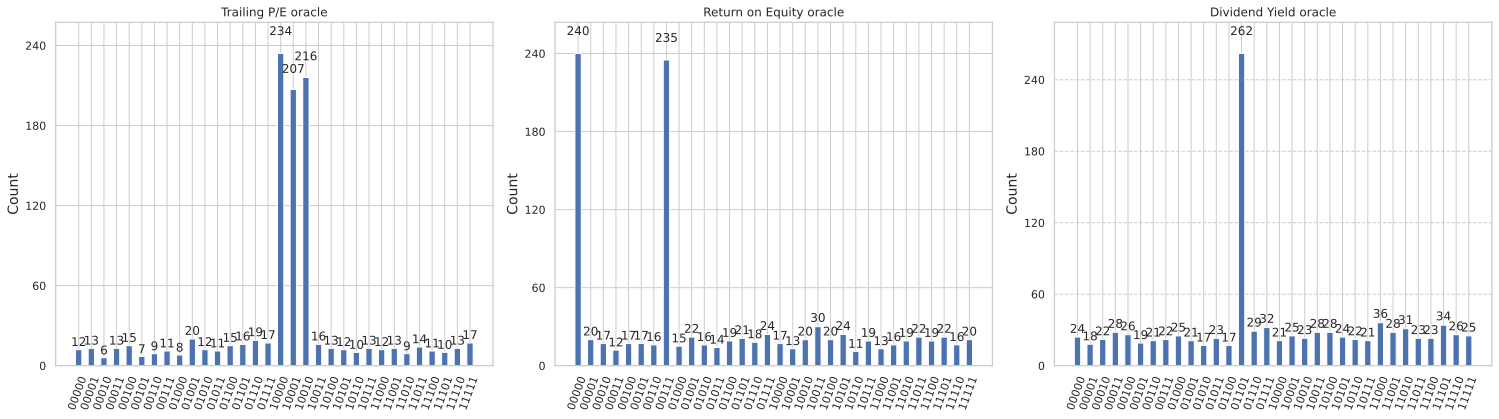

In [10]:
grover_counts = {metric: run(grover_circuit(oracle), noise=noise_model)
                 for metric, oracle in oracles.items()}

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, metric in zip(axes, METRICS):
    plot_histogram(grover_counts[metric], ax=ax)
    ax.set_title(f"{METRIC_LABELS[metric]} oracle")
fig.tight_layout()
save_figure(fig, "04_grover_histograms")

Measurement counts are folded back onto stocks: basis state `i` is stock `i`,
and states beyond the 20th are padding.

In [11]:
def counts_per_stock(counts: dict[str, int], n_stocks: int) -> list[int]:
    """Map measured bitstrings back onto stock indices."""
    totals = [0] * n_stocks
    for bitstring, count in counts.items():
        index = int(bitstring, 2)
        if index < n_stocks:
            totals[index] += count
    return totals


amplification = pd.DataFrame(
    {METRIC_LABELS[metric]: counts_per_stock(grover_counts[metric], len(processed))
     for metric in METRICS},
    index=processed["symbol"],
)
amplification["Total"] = amplification.sum(axis=1)
amplification = amplification.sort_values("Total", ascending=False)
amplification

,Trailing P/E,Return on Equity,Dividend Yield,Total
symbol,,,,
HPQ,16,21,262,299
AAPL,12,240,24,276
AMD,234,17,21,272
NVDA,11,235,22,268
SAP,216,20,23,259
AVGO,207,13,25,245
ADP,16,30,28,74
ACN,17,24,32,73
DELL,19,18,29,66


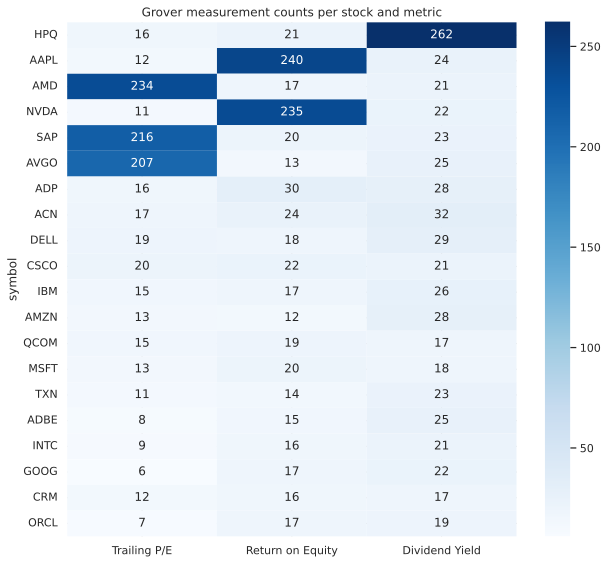

In [12]:
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(amplification.drop(columns="Total"),
            cmap="Blues", annot=True, fmt="g", ax=ax)
ax.set_title("Grover measurement counts per stock and metric")
ax.set_xlabel("")
fig.tight_layout()
save_figure(fig, "05_counts_heatmap")

The amplified states are exactly the classically flagged outliers, so the
quantum search reproduces the classical benchmark. Amplification is partial
rather than absolute: depolarizing noise leaks probability into the unmarked
states, so the peaks land well short of certainty.

In [13]:
amplified = amplification["Total"].nlargest(n_flags)
classical_flagged = set(processed.loc[processed["composite_score"] > 0, "symbol"])

print("amplified by Grover:", sorted(amplified.index))
print("flagged classically:", sorted(classical_flagged))
print("agreement:", set(amplified.index) == classical_flagged)

amplified by Grover: ['AAPL', 'AMD', 'AVGO', 'HPQ', 'NVDA', 'SAP']
flagged classically: ['AAPL', 'AMD', 'AVGO', 'HPQ', 'NVDA', 'SAP']
agreement: True


### Quantum counting on the same oracles

In [14]:
counting_counts = {metric: run(counting_circuit(oracle), noise=noise_model)
                   for metric, oracle in oracles.items()}

counting_summary = []
for metric in METRICS:
    outcome, value, estimate = estimate_marked(counting_counts[metric])
    counting_summary.append({
        "metric": METRIC_LABELS[metric],
        "marked (true)": int(processed[f"{metric}_outlier"].sum()),
        "modal outcome": outcome,
        "phase value": value,
        "M estimate": round(estimate, 2),
    })

pd.DataFrame(counting_summary)

,metric,marked (true),modal outcome,phase value,M estimate
0,Trailing P/E,3,011,6,16.00
1,Return on Equity,2,101,5,27.31
2,Dividend Yield,1,100,1,4.69


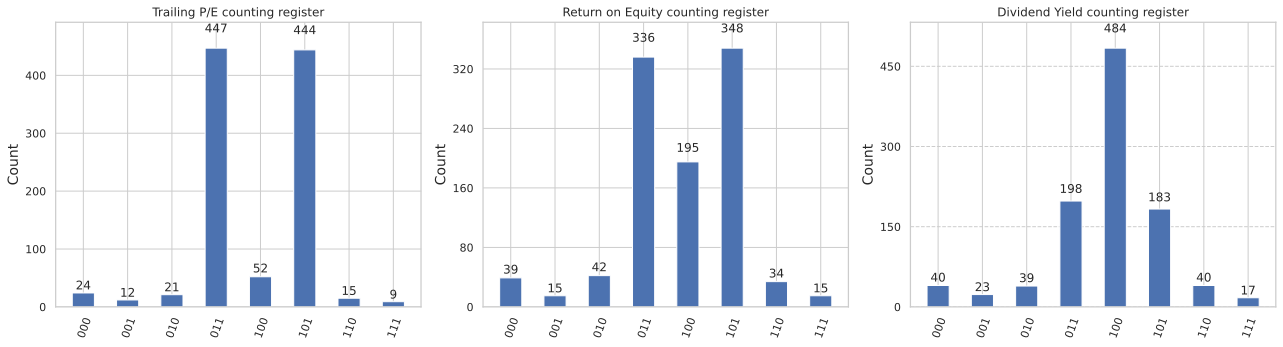

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, METRICS):
    plot_histogram(counting_counts[metric], ax=ax)
    ax.set_title(f"{METRIC_LABELS[metric]} counting register")
fig.tight_layout()
save_figure(fig, "06_counting_histograms")

With three counting qubits the estimator resolves only `M` in
`{0, 4.69, 16, 27.31, 32}`, and the `v` / `2^t - v` degeneracy means a small
marked set can be reported as its complement. The estimates are therefore
useful for order of magnitude and for driving the feedback loop in Experiment
2, not as exact counts. A wider counting register is the direct fix, at the
cost of a deeper circuit and more noise.

## 5. Experiment 2: amplitude encoding and a quantum-tuned threshold

Instead of thresholding classically, the |z-score| vector for return on equity
is normalised and amplitude-encoded, and the threshold is tuned inside the
quantum loop: count the marked states, raise the threshold while too many are
marked, stop once the count falls into the target band.

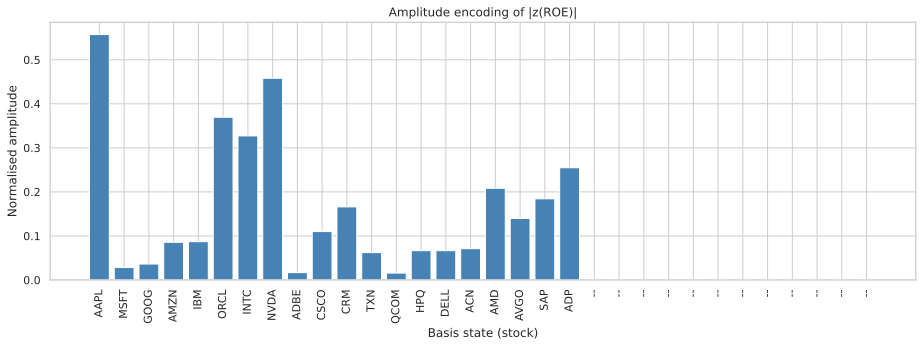

In [16]:
z_scores = processed["returnOnEquity_z"].abs().to_numpy()
state_vector = np.zeros(N_STATES)
state_vector[:len(z_scores)] = z_scores
state_vector /= np.linalg.norm(state_vector)

symbols = list(processed["symbol"]) + ["--"] * (N_STATES - len(processed))

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(range(N_STATES), state_vector, color="steelblue")
ax.set_xticks(range(N_STATES))
ax.set_xticklabels(symbols, rotation=90)
ax.set_xlabel("Basis state (stock)")
ax.set_ylabel("Normalised amplitude")
ax.set_title("Amplitude encoding of |z(ROE)|")
fig.tight_layout()
save_figure(fig, "07_amplitude_encoding")

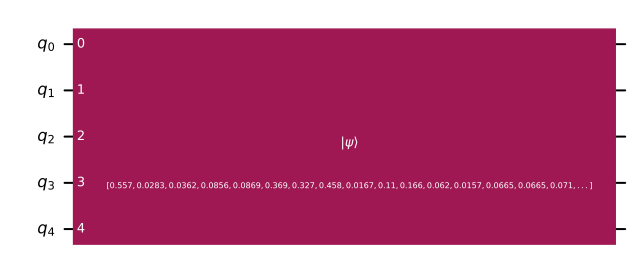

In [17]:
state_prep = QuantumCircuit(N_SYSTEM_QUBITS, name="encode")
state_prep.initialize(state_vector, state_prep.qubits)

fig = state_prep.draw("mpl")
save_figure(fig, "08_state_preparation")
fig

The encoding circuit is shown for reference. The Grover runs below still start
from the uniform superposition, so the encoded amplitudes enter the pipeline
through the threshold the oracle marks rather than through the initial state.
Starting Grover from the encoded state would require a diffusion operator that
inverts about the mean of a non-uniform state; that is left for future work.

In [18]:
def amplitude_oracle(threshold: float, values: np.ndarray, n_states: int = N_STATES) -> Gate:
    """Phase-flip oracle marking every state whose value exceeds `threshold`."""
    return diagonal_oracle(np.flatnonzero(values > threshold), n_states)


TARGET_MARKED = (1, 6)
THRESHOLD_STEP = 0.25
MAX_TUNING_ITERATIONS = 5
INITIAL_THRESHOLD = 1.5

threshold = INITIAL_THRESHOLD
tuning_history, counting_histograms = [], []

for iteration in range(MAX_TUNING_ITERATIONS):
    oracle = amplitude_oracle(threshold, z_scores)
    counts = run(counting_circuit(oracle), seed=SEED + iteration)
    outcome, value, estimate = estimate_marked(counts)

    tuning_history.append({
        "iteration": iteration,
        "threshold": threshold,
        "marked (true)": int((z_scores > threshold).sum()),
        "modal outcome": outcome,
        "M estimate": round(estimate, 2),
    })
    counting_histograms.append(counts)

    if estimate > TARGET_MARKED[1]:
        threshold += THRESHOLD_STEP
    elif estimate < TARGET_MARKED[0]:
        threshold -= THRESHOLD_STEP

tuned_threshold = threshold
tuning = pd.DataFrame(tuning_history)
print(f"tuned threshold: {tuned_threshold:.2f}")
tuning

tuned threshold: 2.25


,iteration,threshold,marked (true),modal outcome,M estimate
0,0,1.50,3,011,16.00
1,1,1.75,2,011,16.00
2,2,2.00,2,011,16.00
3,3,2.25,1,100,4.69
4,4,2.25,1,100,4.69


The loop runs noiseless: it is measuring the counting register five times in
sequence, and the point of the experiment is the feedback behaviour rather
than its noise tolerance. Experiment 1 covers the noisy case.

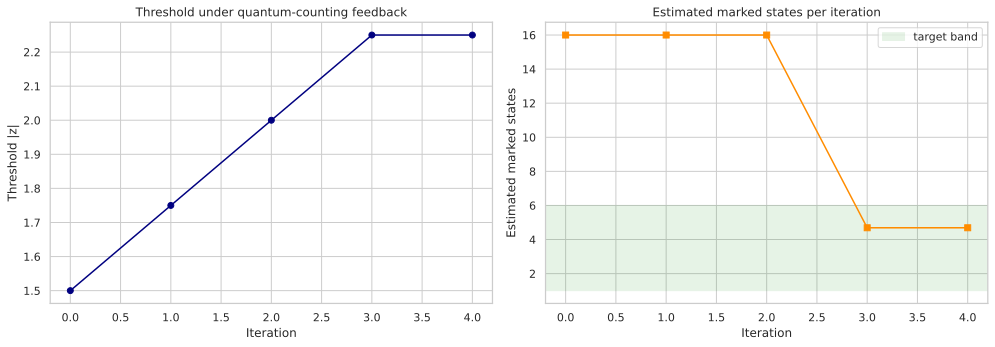

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(tuning["iteration"], tuning["threshold"], marker="o", color="navy")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Threshold |z|")
axes[0].set_title("Threshold under quantum-counting feedback")
axes[1].plot(tuning["iteration"], tuning["M estimate"], marker="s", color="darkorange")
axes[1].axhspan(*TARGET_MARKED, color="green", alpha=0.1, label="target band")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Estimated marked states")
axes[1].set_title("Estimated marked states per iteration")
axes[1].legend()
fig.tight_layout()
save_figure(fig, "09_threshold_convergence")

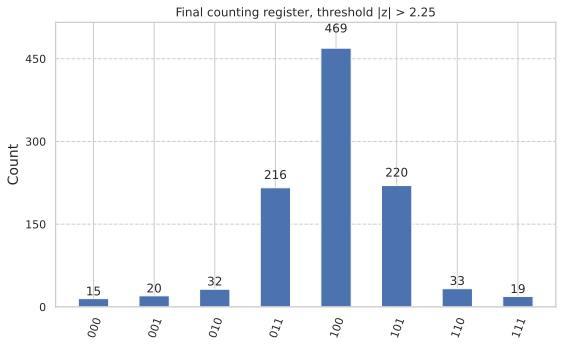

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_histogram(counting_histograms[-1], ax=ax)
ax.set_title(f"Final counting register, threshold |z| > {tuned_threshold:.2f}")
fig.tight_layout()
save_figure(fig, "10_final_counting_histogram")

### Grover search at the tuned threshold

,state,count,index,symbol
28,00000,277,0,AAPL
17,10000,33,16,AMD
31,10011,33,19,ADP
2,01001,32,9,CSCO
6,01111,32,15,ACN


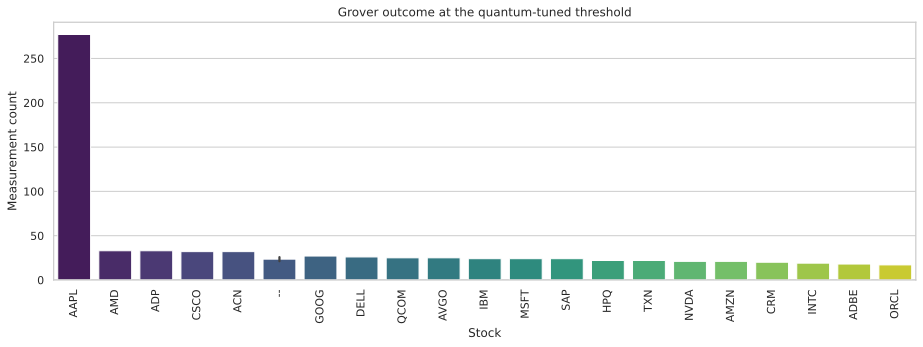

In [21]:
final_oracle = amplitude_oracle(tuned_threshold, z_scores)
final_counts = run(grover_circuit(final_oracle), noise=noise_model)

outcomes = pd.DataFrame(
    {"state": list(final_counts), "count": list(final_counts.values())}
)
outcomes["index"] = outcomes["state"].map(lambda state: int(state, 2))
outcomes["symbol"] = outcomes["index"].map(lambda index: symbols[index])
outcomes = outcomes.sort_values("count", ascending=False)

fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(data=outcomes, x="symbol", y="count", hue="symbol",
            palette="viridis", legend=False, ax=ax)
ax.set_xlabel("Stock")
ax.set_ylabel("Measurement count")
ax.set_title("Grover outcome at the quantum-tuned threshold")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
save_figure(fig, "11_grover_outcome")

outcomes.head(5)

### Comparison with the classical benchmark

classical ROE outliers at |z| > 2.25: ['AAPL']
Grover's top measured state: AAPL


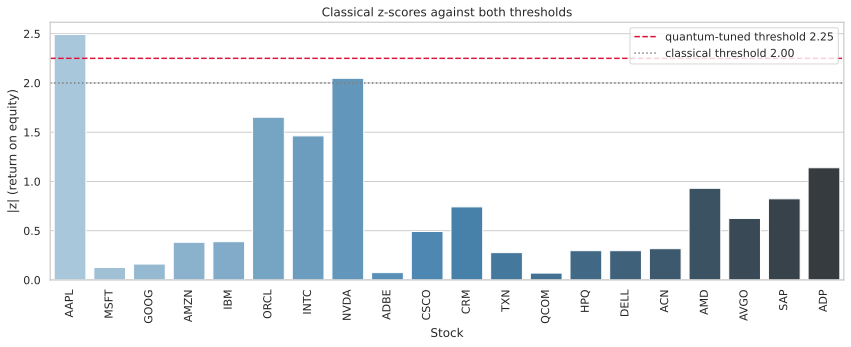

In [22]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=processed, x="symbol", y=processed["returnOnEquity_z"].abs(),
            hue="symbol", palette="Blues_d", legend=False, ax=ax)
ax.axhline(tuned_threshold, color="crimson", linestyle="--",
           label=f"quantum-tuned threshold {tuned_threshold:.2f}")
ax.axhline(threshold_used, color="grey", linestyle=":",
           label=f"classical threshold {threshold_used:.2f}")
ax.set_xlabel("Stock")
ax.set_ylabel("|z| (return on equity)")
ax.set_title("Classical z-scores against both thresholds")
ax.tick_params(axis="x", rotation=90)
ax.legend()
fig.tight_layout()
save_figure(fig, "12_zscores_vs_threshold")

roe_flagged = processed.loc[
    processed["returnOnEquity_z"].abs() > tuned_threshold, "symbol"].tolist()
print(f"classical ROE outliers at |z| > {tuned_threshold:.2f}: {roe_flagged}")
print(f"Grover's top measured state: {outcomes.iloc[0]['symbol']}")

## 6. Summary

- Grover amplified exactly the states the classical z-score benchmark flags,
  in both the binary-indicator and amplitude-encoded setups. The quantum
  pipeline agrees with the classical one; the interest is in the scaling
  argument, not in a different answer.
- Amplification is partial. Under a 1% depolarizing channel the marked peaks
  reach roughly a fifth of the shots each rather than dominating, and the gap
  widens with circuit depth. Confidence falls as depth and iteration count
  rise, which are exactly the quantities that have to grow before the
  quadratic speedup pays for itself.
- Quantum counting with three counting qubits is too coarse to report `M`
  exactly, but it is sufficient to drive the threshold search into the target
  band, which is the role it plays in Experiment 2.
- The classical stage is doing real work: it reduces the search space before
  any qubit is touched. Next steps are a wider counting register, an oracle
  built directly from arithmetic comparison rather than a precomputed
  diagonal, and a dataset large enough for the asymptotics to matter.